[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abhishek12198/entriMiniProject/blob/main/Module_End_Assignment5_Diabetes_ANN.ipynb)

# Diabetes progression with a neural network

Open this notebook in Google Colab with the button above, then use **Runtime → Run all**. Each code cell runs in order, and the tables and plots appear under that cell.

The task is to model how far diabetes progresses over a year from measurements taken at baseline. The target, `progression`, is a numeric score, not a yes-or-no diagnosis. A higher score means the disease advanced further. The ten inputs are age, sex, body mass index, average blood pressure, and six blood-serum measurements.

A small artificial neural network is trained first. A second network, with a wider hidden stack and a lower learning rate, is trained on the same split. Both are scored on the same held-out patients with mean squared error and R-squared. The stack is TensorFlow/Keras, scikit-learn, pandas, NumPy, and Matplotlib.


## 1. Setup


In [1]:
%matplotlib inline

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)


I0000 00:00:1795854295.957363   89700 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795854297.218141   89700 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. Load the dataset

`load_diabetes` returns the classic baseline table: 442 patients and 10 numeric inputs. scikit-learn has already mean-centered each input and scaled it so the sum of squares of each column is 1. The values are therefore small, around a few hundredths, and they are not in the original clinical units.

The column names in the file are short. The names used below are the ones from the dataset description: age, sex, body mass index (`bmi`), average blood pressure (`bp`), total cholesterol (`s1`), LDL (`s2`), HDL (`s3`), the cholesterol ratio (`s4`), a serum triglyceride measure (`s5`), and blood sugar (`s6`).


In [2]:
dataset = load_diabetes()
feature_labels = {
    "age": "Age",
    "sex": "Sex",
    "bmi": "Body mass index",
    "bp": "Blood pressure",
    "s1": "Total cholesterol",
    "s2": "LDL",
    "s3": "HDL",
    "s4": "Cholesterol ratio",
    "s5": "Serum triglycerides",
    "s6": "Blood sugar",
}
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="progression")

print(f"Patients: {X.shape[0]}")
print(f"Features: {X.shape[1]}")
print(f"Progression: min {y.min():.0f}, median {y.median():.0f}, max {y.max():.0f}")
X.head(3)


Patients: 442
Features: 10
Progression: min 25, median 140, max 346


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930


## 3. Missing values and normalisation

A missing serum value cannot be passed into a dense layer. The count is checked on the full table before the split. This published table has no blank cells, so there is nothing to impute.

The columns are already on a shared scale, but that scale is "sum of squares equals 1", not "standard deviation equals 1". A ReLU network is easier to train when each training column has mean 0 and standard deviation 1. `StandardScaler` does that. It is fit on the training patients only, after the split in section 6, and the test patients are transformed with those training statistics. The progression score is left in its original units so the error stays in score points rather than in a standardised number.


In [3]:
missing_features = int(X.isna().sum().sum())
missing_target = int(y.isna().sum())
print(f"Missing feature values: {missing_features} of {X.shape[0] * X.shape[1]}")
print(f"Missing progression values: {missing_target}")
print()
print("Published feature scale (mean, standard deviation):")
print(X.agg(["mean", "std"]).T.round(4).to_string())


Missing feature values: 0 of 4420
Missing progression values: 0

Published feature scale (mean, standard deviation):
     mean     std
age  -0.0  0.0476
sex   0.0  0.0476
bmi  -0.0  0.0476
bp   -0.0  0.0476
s1   -0.0  0.0476
s2    0.0  0.0476
s3   -0.0  0.0476
s4   -0.0  0.0476
s5    0.0  0.0476
s6    0.0  0.0476


## 4. Exploratory data analysis

The progression score runs from 25 to 346. The centre of the table is near 140, and the upper tail reaches past 300, so a model that only predicts the average will still be far from the patients who progress the most.

The correlations use all 442 patients and describe the table. They are not a fitted network. Body mass index and the triglyceride measure rise with progression. HDL is the clear movement in the other direction: higher HDL goes with a lower progression score. Sex barely lines up with the score on its own. Age has a weak positive association. The two scatter plots show the two strongest positive relationships. The cloud is wide, so no single measurement determines the score.


count    442.0
mean     152.1
std       77.1
min       25.0
25%       87.0
50%      140.5
75%      211.5
max      346.0


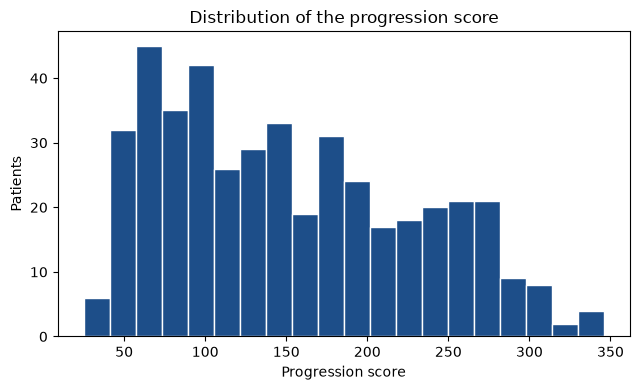


Correlation with progression:
s3    -0.395
sex    0.043
s2     0.174
age    0.188
s1     0.212
s6     0.382
s4     0.430
bp     0.441
s5     0.566
bmi    0.586


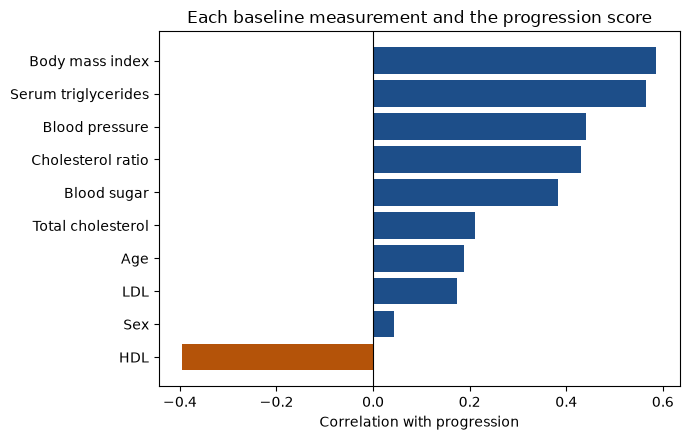

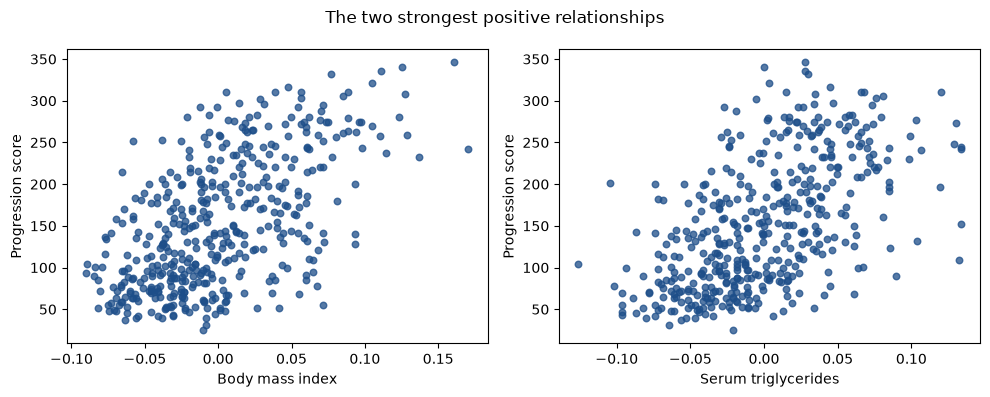

In [4]:
print(y.describe().round(1).to_string())

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(y, bins=20, color="#1d4e89", edgecolor="white")
ax.set_xlabel("Progression score")
ax.set_ylabel("Patients")
ax.set_title("Distribution of the progression score")
fig.tight_layout()
plt.show()

correlation = X.copy()
correlation["progression"] = y
association = correlation.corr()["progression"].drop("progression").sort_values()
print()
print("Correlation with progression:")
print(association.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4.5))
labels = [feature_labels[name] for name in association.index]
colors = ["#b45309" if value < 0 else "#1d4e89" for value in association]
ax.barh(labels, association.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with progression")
ax.set_title("Each baseline measurement and the progression score")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["bmi", "s5"]):
    axis.scatter(X[column], y, s=22, alpha=0.75, color="#1d4e89")
    axis.set_xlabel(feature_labels[column])
    axis.set_ylabel("Progression score")
fig.suptitle("The two strongest positive relationships")
fig.tight_layout()
plt.show()


## 5. A first network

The first network has one hidden layer of 8 ReLU units and a single linear output.

ReLU, `max(0, z)`, is the activation on the hidden layer. It lets the layer turn a measurement off when the weighted sum is negative, and pass it through when the sum is positive. That is enough to combine body mass index, blood pressure, and the serum columns without forcing the score through a probability curve.

The output activation is linear. The progression score is an unbounded number between 25 and 346, not a class probability, so a sigmoid or softmax would squeeze the prediction into the wrong range.

The loss is mean squared error, the average squared gap between the predicted score and the recorded score. Large misses count more than small ones. The optimiser is Adam with a learning rate of 0.01, which is a short first training run of 80 epochs.


In [5]:
def build_baseline():
    network = keras.Sequential([
        layers.Input(shape=(10,)),
        layers.Dense(8, activation="relu"),
        layers.Dense(1, activation="linear"),
    ], name="baseline_ann")
    network.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.01),
        loss="mse",
        metrics=["mae"],
    )
    return network

baseline = build_baseline()
baseline.summary()


Model: "baseline_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97 (388.00 B)

 Trainable params: 97 (388.00 B)

 Non-trainable params: 0 (0.00 B)

## 6. Train on one holdout

Twenty percent of the patients are held out, with `random_state=42`. That is 353 training patients and 89 test patients. The scaler is fit on the training patients, then applied to both sides. The test patients are not used to choose weights or to stop training in this first run. Training loss is mean squared error on the scaled inputs and the original progression score.


Training patients: 353
Test patients: 89
Training columns after scaling: mean of means = -0.000000, mean of stds = 1.0000


Epochs run: 80
Final training MSE: 2933.7


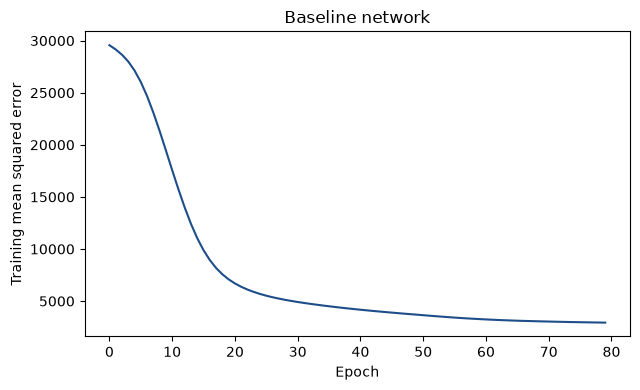

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training patients: {len(X_train)}")
print(f"Test patients: {len(X_test)}")
print(
    "Training columns after scaling: "
    f"mean of means = {X_train_scaled.mean():.6f}, "
    f"mean of stds = {X_train_scaled.std(axis=0).mean():.4f}"
)

tf.random.set_seed(42)
baseline = build_baseline()
baseline_history = baseline.fit(
    X_train_scaled,
    y_train,
    epochs=80,
    batch_size=32,
    verbose=0,
)
print(f"Epochs run: {len(baseline_history.history['loss'])}")
print(f"Final training MSE: {baseline_history.history['loss'][-1]:.1f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(baseline_history.history["loss"], color="#1d4e89")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training mean squared error")
ax.set_title("Baseline network")
fig.tight_layout()
plt.show()


## 7. Test performance

Mean squared error and R-squared are computed on the 89 test patients. R-squared is the share of progression-score variation the predictions capture. Mean absolute error is included so the typical miss can be read in score points. The dashed line on the plot is a perfect prediction.


Test MSE: 2945.9    RMSE: 54.3    MAE: 43.1    R-squared: 0.4440


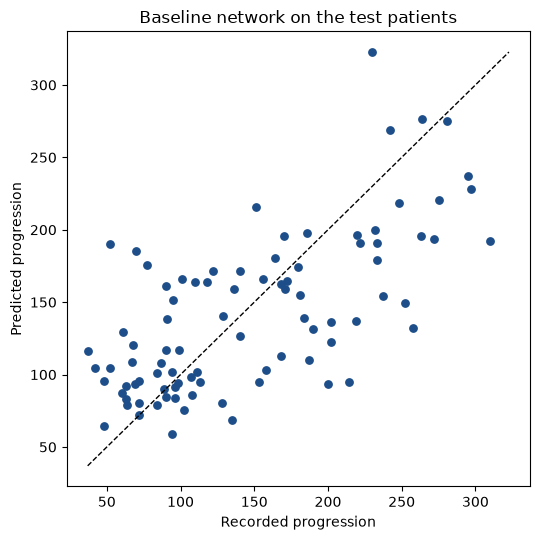

In [7]:
def score_model(name, network):
    predicted = network.predict(X_test_scaled, verbose=0).ravel()
    mse = mean_squared_error(y_test, predicted)
    return {
        "model": name,
        "mse": mse,
        "rmse": np.sqrt(mse),
        "mae": mean_absolute_error(y_test, predicted),
        "r2": r2_score(y_test, predicted),
        "predicted": predicted,
    }

baseline_score = score_model("Baseline, 8 ReLU units", baseline)
print(
    f"Test MSE: {baseline_score['mse']:.1f}    "
    f"RMSE: {baseline_score['rmse']:.1f}    "
    f"MAE: {baseline_score['mae']:.1f}    "
    f"R-squared: {baseline_score['r2']:.4f}"
)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_test, baseline_score["predicted"], s=28, color="#1d4e89")
low = min(y_test.min(), baseline_score["predicted"].min())
high = max(y_test.max(), baseline_score["predicted"].max())
ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Recorded progression")
ax.set_ylabel("Predicted progression")
ax.set_title("Baseline network on the test patients")
fig.tight_layout()
plt.show()


## 8. A second architecture

The first network has eight hidden units, a learning rate of 0.01, and a fixed run of 80 epochs. The second network changes the width, the learning rate, and the length of training. It is still a regression network: mean squared error, Adam, and one linear output.

Two ReLU layers replace the single layer of eight units. The first has 64 units and the second has 16. The extra width can mix body mass index, blood pressure, and the serum columns before the score is produced. ReLU stays the hidden activation, and the output stays linear, because the progression score is still an unbounded number.

The learning rate is lowered from 0.01 to 0.001, and training runs for 250 epochs on all 353 training patients. A higher rate on this small table steps past a good fit. Holding out a validation slice for early stopping was tried as well. It left the network with fewer patients to learn from, and the test error rose, so that slice is not used in the network reported here. The 89 test patients are still untouched.


Model: "improved_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,761 (6.88 KB)

 Trainable params: 1,761 (6.88 KB)

 Non-trainable params: 0 (0.00 B)

Epochs run: 250
Final training MSE: 2500.1


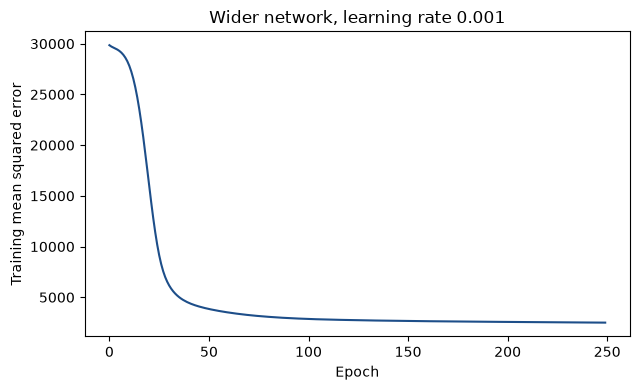

In [8]:
def build_improved():
    network = keras.Sequential([
        layers.Input(shape=(10,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="linear"),
    ], name="improved_ann")
    network.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"],
    )
    return network

tf.random.set_seed(42)
improved = build_improved()
improved.summary()
improved_history = improved.fit(
    X_train_scaled,
    y_train,
    epochs=250,
    batch_size=32,
    verbose=0,
)
print(f"Epochs run: {len(improved_history.history['loss'])}")
print(f"Final training MSE: {improved_history.history['loss'][-1]:.1f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(improved_history.history["loss"], color="#1d4e89")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training mean squared error")
ax.set_title("Wider network, learning rate 0.001")
fig.tight_layout()
plt.show()


## 9. Did the changes help?

Both networks are scored on the same 89 test patients. A lower mean squared error is better. A higher R-squared is better. The wider network is an improvement only if the holdout error falls.


In [9]:
improved_score = score_model("Improved, 64 then 16 ReLU units", improved)
comparison = pd.DataFrame([
    {key: baseline_score[key] for key in ["model", "mse", "rmse", "mae", "r2"]},
    {key: improved_score[key] for key in ["model", "mse", "rmse", "mae", "r2"]},
])
show = comparison.copy()
for column in ["mse", "rmse", "mae"]:
    show[column] = show[column].map(lambda value: f"{value:,.1f}")
show["r2"] = show["r2"].map(lambda value: f"{value:.4f}")
show = show.rename(columns={
    "model": "Network",
    "mse": "MSE",
    "rmse": "RMSE",
    "mae": "MAE",
    "r2": "R-squared",
})
print(show.to_string(index=False))

mse_change = baseline_score["mse"] - improved_score["mse"]
r2_change = improved_score["r2"] - baseline_score["r2"]
print()
print(f"Change in test MSE (baseline minus improved): {mse_change:.1f}")
print(f"Change in test R-squared (improved minus baseline): {r2_change:.4f}")
if mse_change > 0:
    print("The wider network has the lower test error. It is the network to keep.")
else:
    print("The wider network did not lower the test error. The baseline is the network to keep.")


                        Network     MSE RMSE  MAE R-squared
         Baseline, 8 ReLU units 2,945.9 54.3 43.1    0.4440
Improved, 64 then 16 ReLU units 2,763.0 52.6 42.1    0.4785

Change in test MSE (baseline minus improved): 182.9
Change in test R-squared (improved minus baseline): 0.0345
The wider network has the lower test error. It is the network to keep.


## 10. What the holdout says

The wider network is the one to keep. On the 89 test patients its mean squared error is 2,763.0, against 2,945.9 for the eight-unit network. R-squared rises from 0.4440 to 0.4785, and the mean absolute error falls from 43.1 to 42.1 score points.

The change that produced that drop is concrete. The hidden layer grew from 8 ReLU units to two ReLU layers of 64 and 16. The learning rate fell from 0.01 to 0.001, and training ran for 250 epochs instead of 80. The loss stayed mean squared error, and the output stayed a single linear unit.

Body mass index (correlation 0.586) and the triglyceride measure (s5, 0.566) are the baseline measurements that move most clearly with the progression score. HDL (s3, -0.395) moves the other way. Using all ten measurements, the wider network captures about 48% of the score's variation on patients it was not trained on. The rest of the variation is not in this baseline table.
